# Dar_046 - Plasma: native modes, charging context and calendar coverage

## Questions
- How do all downloaded native ESA files compare with the earlier first/last-day monthly cohort?
- What do ion/electron full, reduced and burst modes support after quality, clock and nominal-day checks?
- How do density, temperature and spacecraft potential vary by UTC month, quarter, four-month term, half-year, year, two-year window and calendar season?
- How do matched daily ion/electron, P1/P2 and related native/merged summaries compare without pretending they are co-located instantaneous observations?
- Which evidence guards and conditional operational requirements follow?

All selected ESA files are read. Accepted P1/P2 merged summaries are reused with their provenance. Counts are record fractions, not elapsed valid exposure. Spacecraft potential is not candidate-surface voltage. DJF/MAM/JJA/SON are calendar labels, not lunar seasons. No pipeline integration.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'env_algo_task/EDA').is_dir())
sys.path.insert(0,str(root/'env_algo_task/EDA/Moon/Stage3_Requirements'))
from stage3_plasma_eda import execute

## Execute the full native-file study
The sample validation is separate. This saved notebook runs the full selected native cohort, applies quality/time checks and writes a completed provenance run.

In [2]:
folder,findings=execute(sample=False)
display(findings)

Reading all selected ESA files (sample first/last only when requested)


{
  "subject": "plasma_charging",
  "sample": false,
  "full_downloaded_ESA_files": true,
  "analysed_ESA_files": 1173,
  "mode_file_rows": 7038,
  "daily_rows": 18939,
  "quality_zero_records": 13252374,
  "recorded_mode_records": 53860929,
  "ambiguous_or_missing_clock_mode_records": 4872,
  "calendar_kinds": [
    "month",
    "quarter",
    "four_month_term",
    "half_year",
    "year",
    "two_year",
    "calendar_season"
  ],
  "tables": {
    "esa_daily_context": 18939,
    "esa_series_catalog": 18,
    "native_file_quality": 7038,
    "quality_flag_frequencies": 30017,
    "native_quality_years": 24,
    "calendar_context": 4176,
    "matched_June_October_years": 180,
    "matched_daily_values": 4791,
    "matched_daily_summary": 5,
    "crosscheck_Dar044": 5,
    "stage4_plasma_proposals": 6
  },
  "base_conclusion": "Full native ESA coverage improves mode-specific plasma/spacecraft-potential and quality/cadence context. It does not establish surface voltage, discharge/ESD r

{'subject': 'plasma_charging',
 'sample': False,
 'full_downloaded_ESA_files': True,
 'analysed_ESA_files': 1173,
 'mode_file_rows': 7038,
 'daily_rows': 18939,
 'quality_zero_records': 13252374,
 'recorded_mode_records': 53860929,
 'ambiguous_or_missing_clock_mode_records': 4872,
 'calendar_kinds': ['month',
  'quarter',
  'four_month_term',
  'half_year',
  'year',
  'two_year',
  'calendar_season'],
 'tables': {'esa_daily_context': 18939,
  'esa_series_catalog': 18,
  'native_file_quality': 7038,
  'quality_flag_frequencies': 30017,
  'native_quality_years': 24,
  'calendar_context': 4176,
  'matched_June_October_years': 180,
  'matched_daily_values': 4791,
  'matched_daily_summary': 5,
  'crosscheck_Dar044': 5,
  'stage4_plasma_proposals': 6},
 'base_conclusion': 'Full native ESA coverage improves mode-specific plasma/spacecraft-potential and quality/cadence context. It does not establish surface voltage, discharge/ESD risk, a monotonic safe-density ranking or a mission-operable si

## Native modes, flags, clocks and cadence
Keep species and observing mode separate; anomalous timestamps and nonzero flags are not hidden.

,mode,year,files,recorded,quality_zero,median_daily_good_fraction,ambiguous_clock_records,outside_nominal_day,median_file_spacing_s,pooled_record_good_fraction,interpretation
0,peeb,2023,212,35236,20718,0.666667,188.0,2.0,4.299021,0.587978,"record fractions, not elapsed valid-time cover..."
1,peeb,2024,360,55429,31804,0.686346,108.0,0.0,4.300589,0.573779,"record fractions, not elapsed valid-time cover..."
2,peeb,2025,362,53180,26147,0.569108,74.0,2.0,4.302869,0.491670,"record fractions, not elapsed valid-time cover..."
3,peeb,2026,239,31479,18658,0.697581,6.0,1.0,4.305150,0.592713,"record fractions, not elapsed valid-time cover..."
4,peef,2023,212,1538269,1041887,0.715062,284.0,45.0,4.298900,0.677311,"record fractions, not elapsed valid-time cover..."
5,peef,2024,360,2481021,1703785,0.752230,412.0,88.0,4.300615,0.686727,"record fractions, not elapsed valid-time cover..."
6,peef,2025,362,2331562,1412668,0.629361,314.0,89.0,4.302938,0.605889,"record fractions, not elapsed valid-time cover..."
7,peef,2026,239,1499770,1030646,0.724359,666.0,66.0,4.305230,0.687203,"record fractions, not elapsed valid-time cover..."
8,peer,2023,212,4128308,167102,0.030104,78.0,9370.0,4.298833,0.040477,"record fractions, not elapsed valid-time cover..."
9,peer,2024,360,6971123,245310,0.029074,68.0,15912.0,4.300483,0.035189,"record fractions, not elapsed valid-time cover..."


,mode,flag_value,records
0,peeb,0,97325
1,peeb,128,74371
2,peeb,130,2
3,peeb,144,99
4,peeb,16,162
...,...,...,...
75,peir,32,467998
76,peir,34,1
77,peir,40,25784
78,peir,8,624137


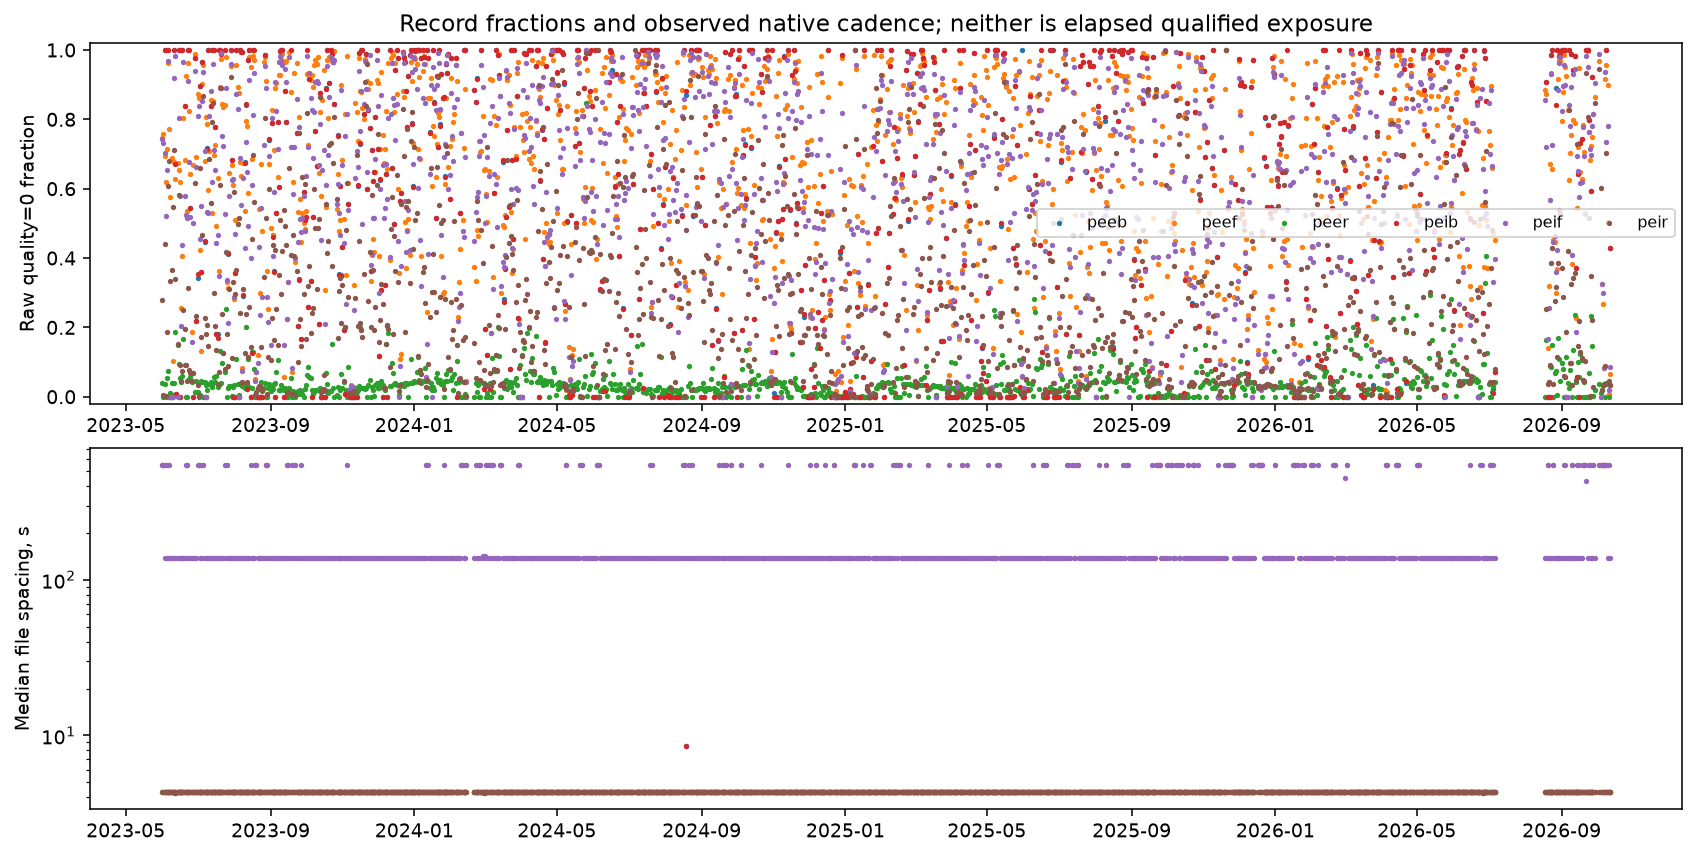

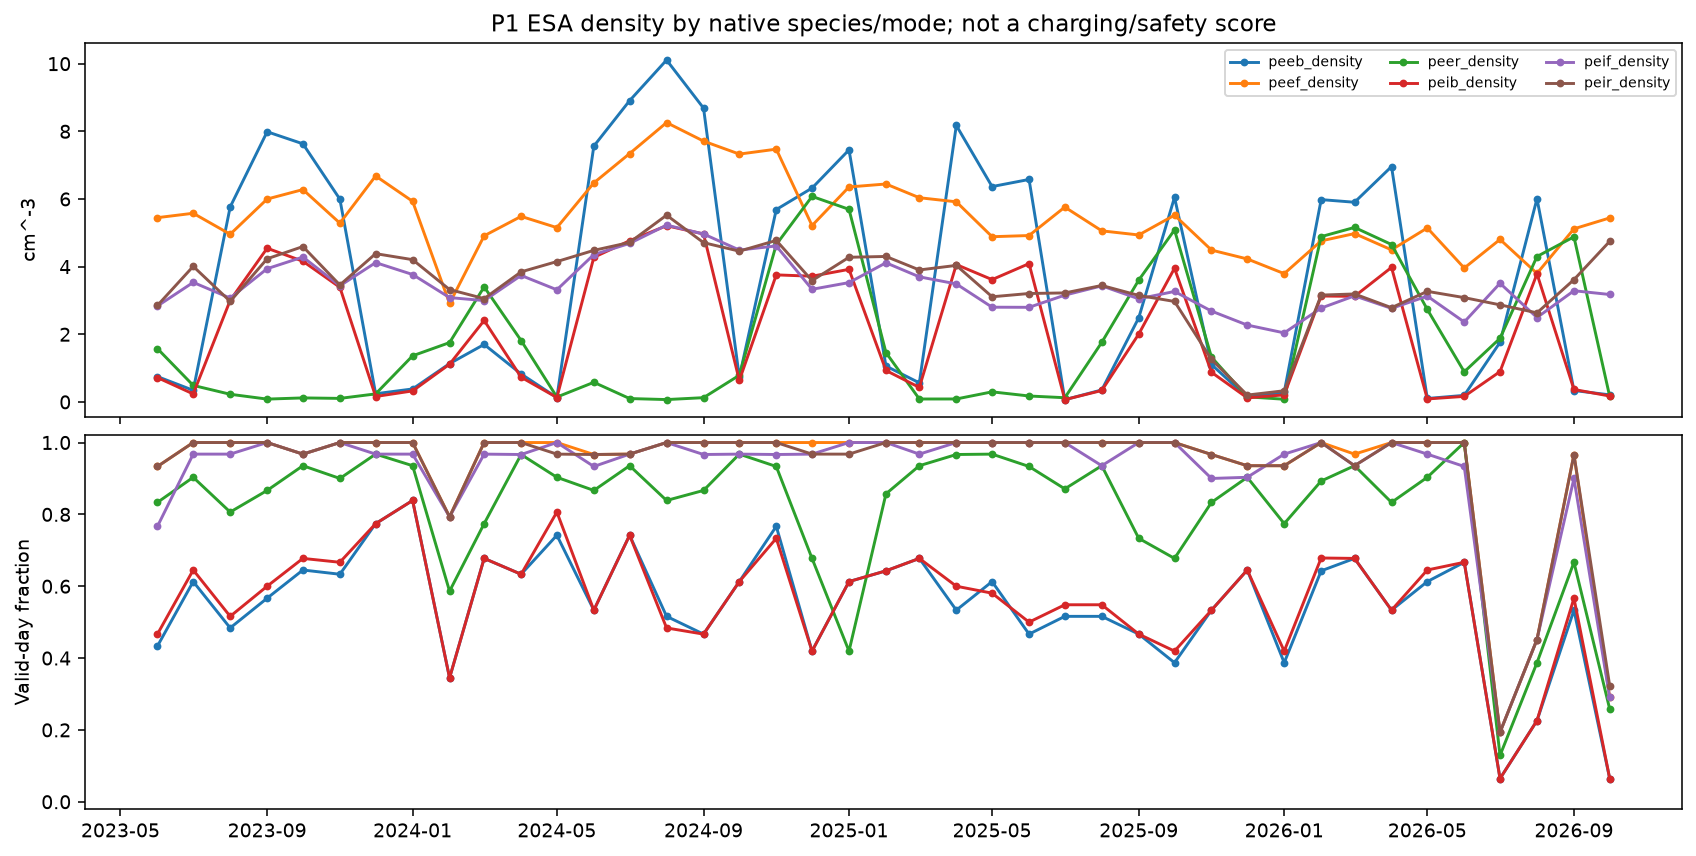

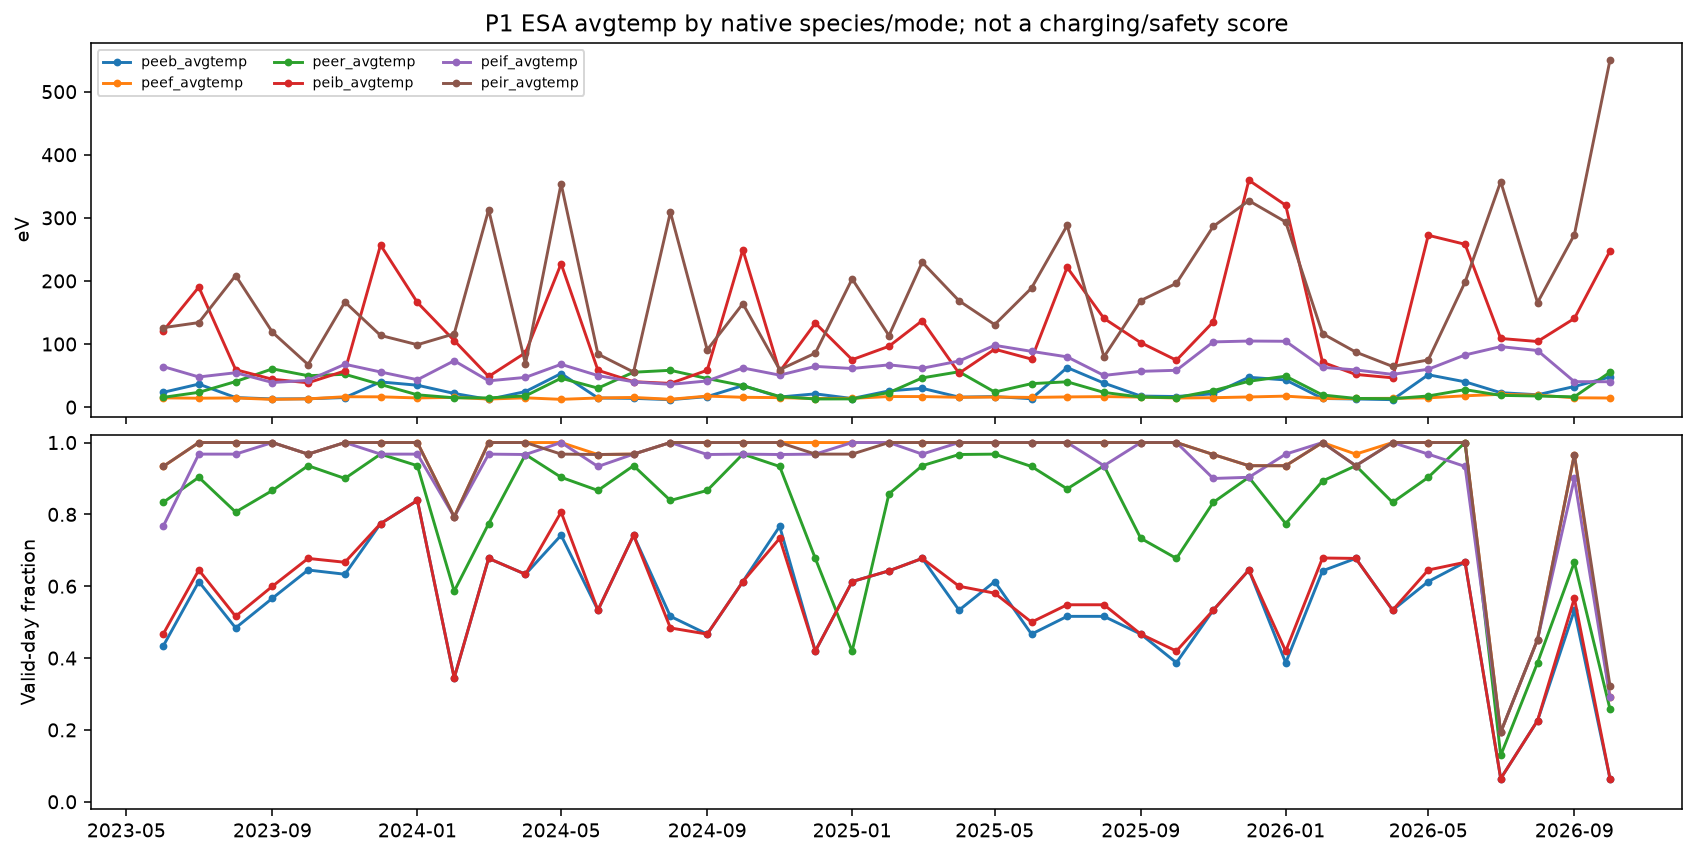

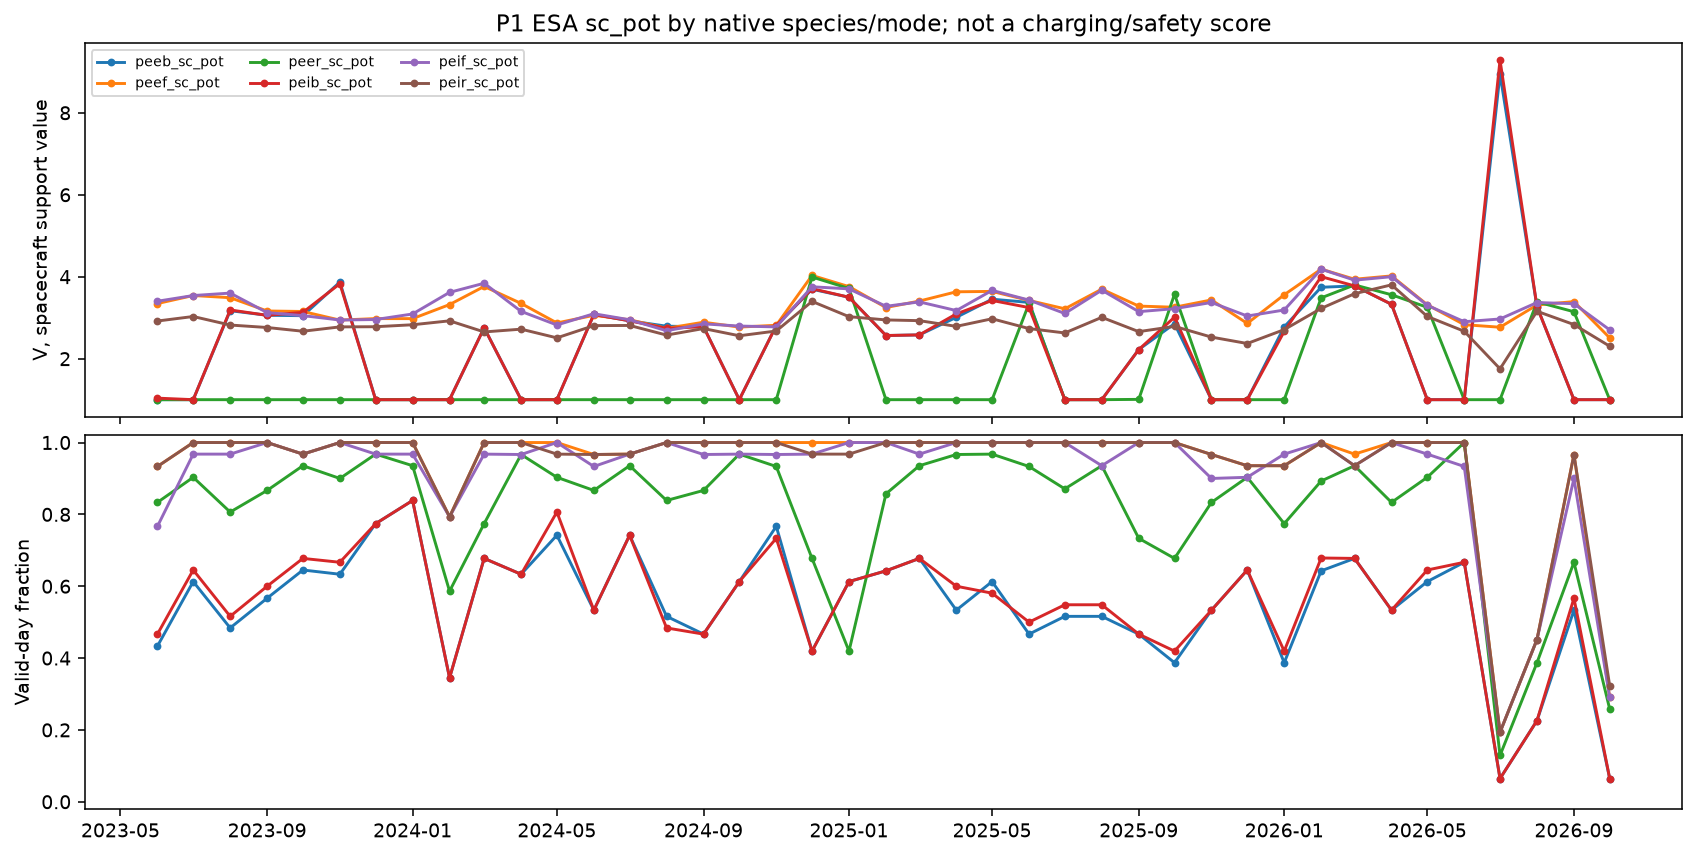

In [3]:
display(pd.read_csv(folder/'native_quality_years.csv'))
display(pd.read_csv(folder/'quality_flag_frequencies.csv').groupby(['mode','flag_value'],as_index=False).records.sum())
for name in ['mode_quality_and_cadence','esa_monthly_density','esa_monthly_avgtemp','esa_monthly_sc_pot']:
    display(Image(filename=str(folder/(name+'.png'))))

## Calendar comparisons
Full calendar denominators expose partial windows. Unobserved days remain missing. The fixed June-October comparison does not equate orbital geometry or equalize mode coverage.

In [4]:
calendar=pd.read_csv(folder/'calendar_context.csv')
display(calendar.groupby('period_kind').size().rename('rows'))
display(pd.read_csv(folder/'matched_June_October_years.csv').head(30))

period_kind
calendar_season     624
four_month_term     486
half_year           348
month              1774
quarter             622
two_year            138
year                184
Name: rows, dtype: int64

,series_id,year,months_inclusive,expected_days,recorded_days,valid_days,median_daily_value,p05_daily_value,p95_daily_value,maximum_daily_value,interpretation
0,ESA_v01_thb_peeb_avgtemp,2023,06-10,153,104,84,16.597218,8.146970,96.470907,177.174095,"same calendar months, not a trend-significance..."
1,ESA_v01_thb_peeb_avgtemp,2024,06-10,153,106,88,15.224477,8.454479,78.770888,177.321655,"same calendar months, not a trend-significance..."
2,ESA_v01_thb_peeb_avgtemp,2025,06-10,153,85,72,22.185295,10.451038,84.924534,189.861206,"same calendar months, not a trend-significance..."
3,ESA_v01_thb_peeb_avgtemp,2026,06-10,153,53,47,34.527760,11.450038,123.513073,198.551712,"same calendar months, not a trend-significance..."
4,ESA_v01_thb_peeb_density,2023,06-10,153,104,84,5.767440,0.048128,24.104968,53.940075,"same calendar months, not a trend-significance..."
5,ESA_v01_thb_peeb_density,2024,06-10,153,106,88,7.940571,0.049946,21.284742,26.934704,"same calendar months, not a trend-significance..."
6,ESA_v01_thb_peeb_density,2025,06-10,153,85,72,1.479266,0.029639,15.151125,21.077123,"same calendar months, not a trend-significance..."
7,ESA_v01_thb_peeb_density,2026,06-10,153,53,47,0.300475,0.044026,10.778164,17.119661,"same calendar months, not a trend-significance..."
8,ESA_v01_thb_peeb_sc_pot,2023,06-10,153,104,84,2.819029,1.000000,26.788833,71.873672,"same calendar months, not a trend-significance..."
9,ESA_v01_thb_peeb_sc_pot,2024,06-10,153,106,88,2.739940,1.000000,20.101969,54.982628,"same calendar months, not a trend-significance..."


## Cross-checks and associations
Earlier screening values/support must be unchanged on shared days. Matched daily associations are descriptive and do not establish quasi-neutrality, causation or charging limits.

,quantity,previous_daily_rows,matched_rows,support_changed_rows,maximum_absolute_difference,conclusion
0,daily_median,1374,1374,0,5.684342e-14,full-file cohort expansion must preserve ident...
1,daily_max,1374,1374,0,2.273737e-13,full-file cohort expansion must preserve ident...
2,daily_p95,1374,1374,0,4.547474e-13,full-file cohort expansion must preserve ident...
3,recorded_samples,1374,1374,0,0.000000e+00,full-file cohort expansion must preserve ident...
4,valid_samples,1374,1374,0,0.000000e+00,full-file cohort expansion must preserve ident...


,comparison,left_series,right_series,paired_valid_dates,spearman_descriptive,median_positive_daily_ratio,interpretation
0,P1_ion_vs_electron_f,ESA_v01_thb_peif_density,ESA_v01_thb_peef_density,1139,0.954614,0.634885,descriptive common-day association; no causali...
1,P1_ion_vs_electron_r,ESA_v01_thb_peir_density,ESA_v01_thb_peer_density,1013,0.222098,1.398705,descriptive common-day association; no causali...
2,P1_ion_vs_electron_b,ESA_v01_thb_peib_density,ESA_v01_thb_peeb_density,680,0.985151,0.632655,descriptive common-day association; no causali...
3,P1_vs_P2_full_mode_daily,PLASMA_THB_v01_thb_peif_densityQ_all_positions,P2_v01_thc_peif_densityQ_all_positions,941,0.938340,0.875000,descriptive common-day association; no causali...
4,P1_native_vs_merged_product,ESA_v01_thb_peif_density,PLASMA_THB_v01_thb_peif_densityQ_all_positions,1018,0.997583,0.999921,descriptive common-day association; no causali...


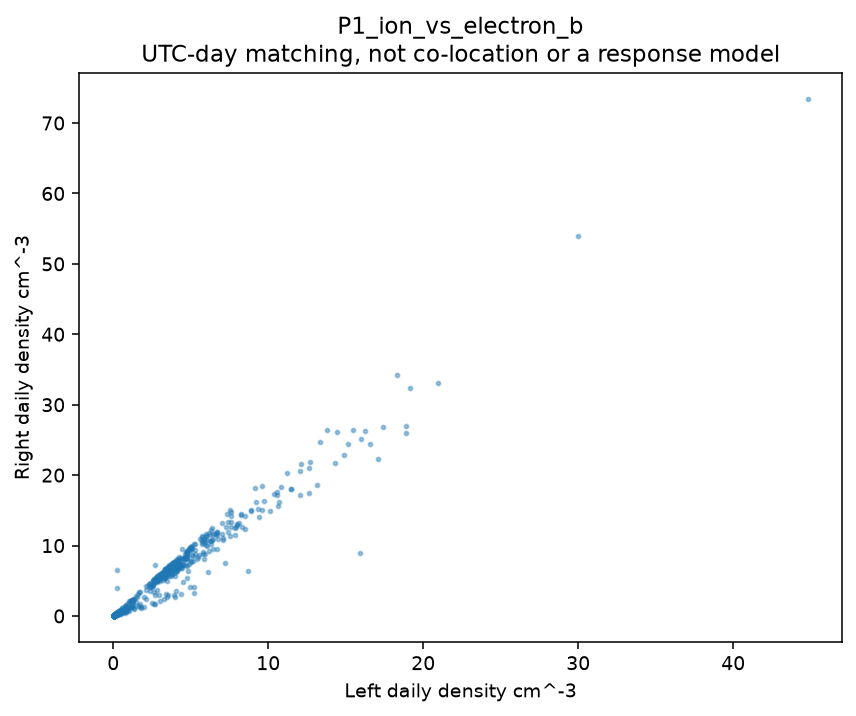

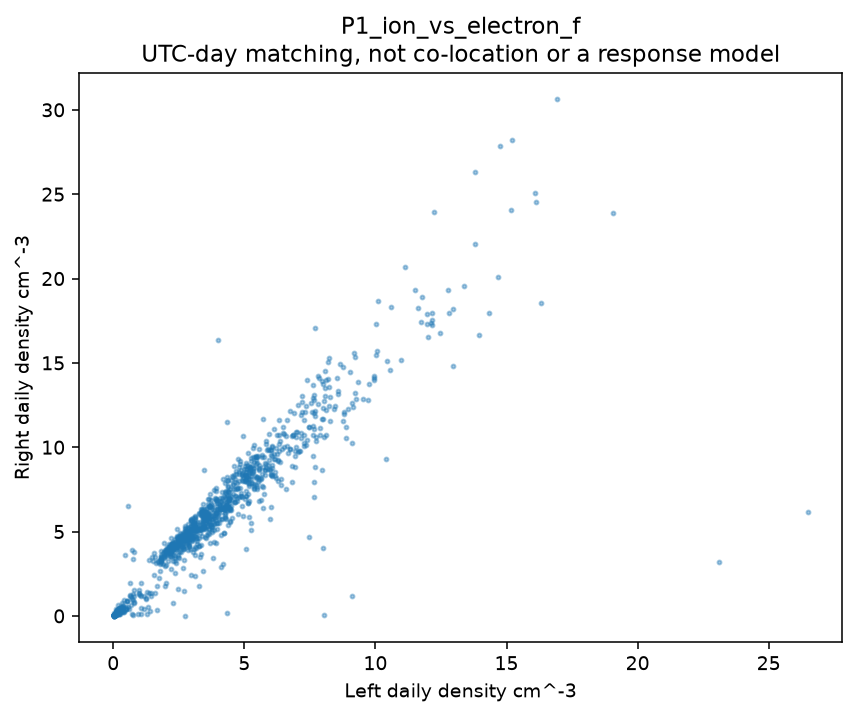

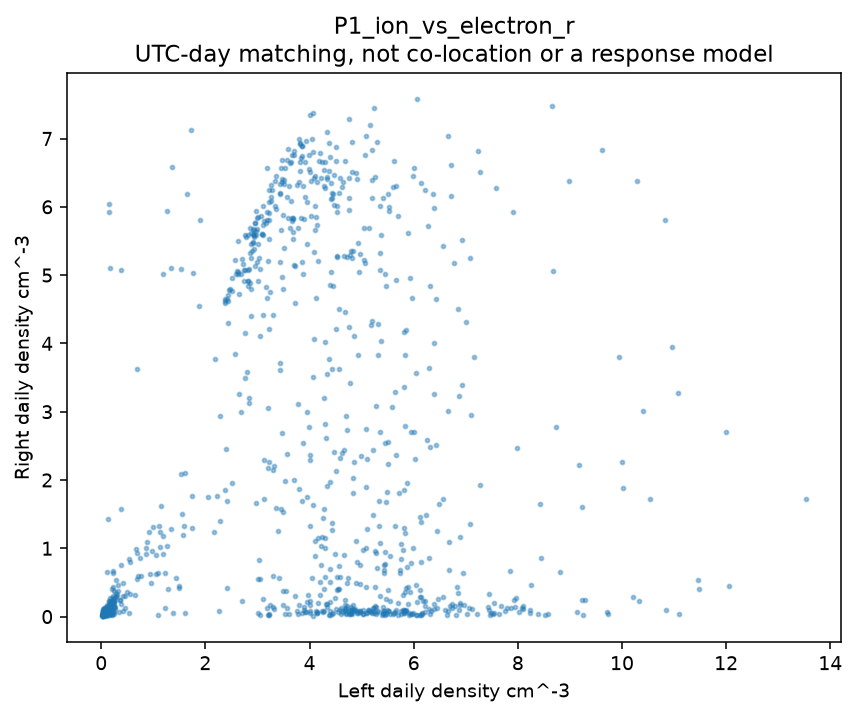

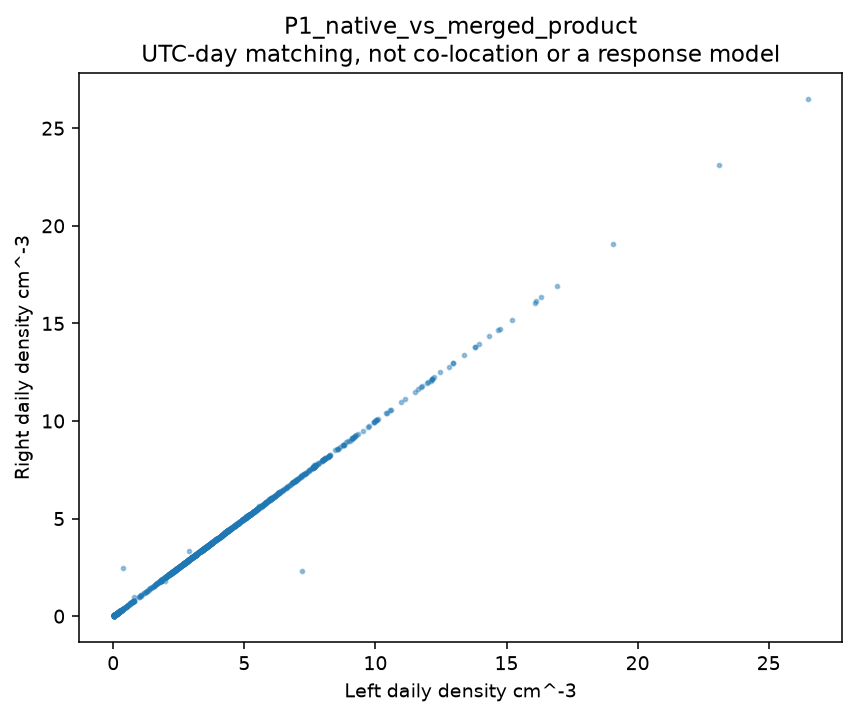

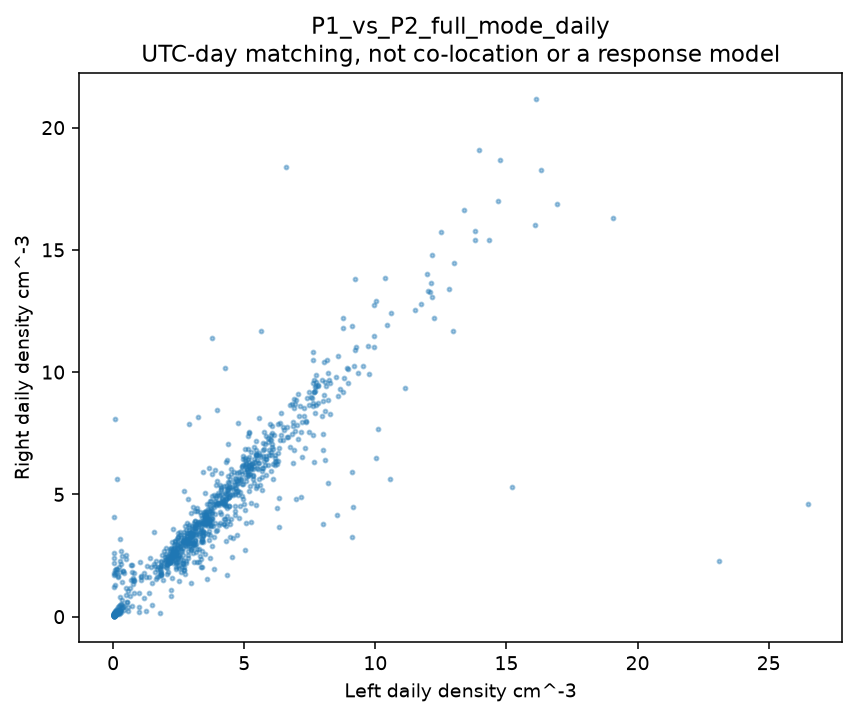

In [5]:
display(pd.read_csv(folder/'crosscheck_Dar044.csv'))
display(pd.read_csv(folder/'matched_daily_summary.csv'))
for p in sorted(folder.glob('matched_*.png')): display(Image(filename=str(p)))

## Stage 4 proposals
No numerical charging limit or preference weight is adopted. Unknown local response, capability or applicability remains Unknown. These proposals are not consumed by Stage 5.

In [6]:
display(pd.read_csv(folder/'stage4_plasma_proposals.csv')[['id','classification','title','current_outcome','decision_logic']])

,id,classification,title,current_outcome,decision_logic
0,PL-G01,evidence_guard,Native quality and clocks before mode comparisons,Unknown,Virtual Q arrays have no stored data; explicit...
1,PL-G02,evidence_guard,Modes/species/cadence are not interchangeable,Unknown,No pooling as identical observations or conver...
2,PL-G03,evidence_guard,Spacecraft geometry and potential are not surf...,Unknown,Neither spacecraft-potential moments nor densi...
3,PL-H01,conditional_hard_constraint,Essential-system charging/ESD capability,Unknown,Passed only when supported local demand meets ...
4,PL-S01,conditional_soft_preference,Reduced qualified charging-management burden,Unknown,Preference may use a validated operational bur...
5,PL-G04,evidence_guard,Calendar associations are not causal or foreca...,Unknown,Keep partial windows and sample-matching limit...


## Base conclusion
The full cohort improves mode-specific plasma context, coverage and clock/quality interpretation. It does **not** establish candidate surface charging or a monotonic lowest-density/voltage safety ranking. Compare qualified local demand with applicable hardware capability before an operational decision.

In [7]:
print(json.dumps(findings,indent=2))
print('Completed run:',folder)

{
  "subject": "plasma_charging",
  "sample": false,
  "full_downloaded_ESA_files": true,
  "analysed_ESA_files": 1173,
  "mode_file_rows": 7038,
  "daily_rows": 18939,
  "quality_zero_records": 13252374,
  "recorded_mode_records": 53860929,
  "ambiguous_or_missing_clock_mode_records": 4872,
  "calendar_kinds": [
    "month",
    "quarter",
    "four_month_term",
    "half_year",
    "year",
    "two_year",
    "calendar_season"
  ],
  "tables": {
    "esa_daily_context": 18939,
    "esa_series_catalog": 18,
    "native_file_quality": 7038,
    "quality_flag_frequencies": 30017,
    "native_quality_years": 24,
    "calendar_context": 4176,
    "matched_June_October_years": 180,
    "matched_daily_values": 4791,
    "matched_daily_summary": 5,
    "crosscheck_Dar044": 5,
    "stage4_plasma_proposals": 6
  },
  "base_conclusion": "Full native ESA coverage improves mode-specific plasma/spacecraft-potential and quality/cadence context. It does not establish surface voltage, discharge/ESD r